# gcn and graphsage on cora, with the oversmoothing, oversquashing, equivariance, hyperparameter and expressivity experiments from shraban's lab guide
every model below is built with pytorch geometric layers only (GCNConv, SAGEConv, GINConv, SGConv) -- there is no hand-written message passing anywhere in this notebook

install pytorch geometric

In [5]:
!pip install torch_geometric -q


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


import every library used in this notebook

In [6]:
import random
import math
import itertools
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt

from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import to_networkx, from_networkx, dropout_edge, to_dense_adj, degree
from torch_geometric.nn import GCNConv, SAGEConv, GINConv, SGConv
from torch_geometric.nn.conv.gcn_conv import gcn_norm
from torch_geometric.data import Data

fix every random seed so results are reproducible

In [7]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)

## part 1 -- loading cora

load the full cora dataset with row-normalized features

In [8]:
dataset = Planetoid(root="data/Cora", name="Cora", transform=NormalizeFeatures())
data = dataset[0]

Processing...
Done!


print basic statistics about the dataset

In [9]:
def print_dataset_stats(dataset, data):
    print("number of graphs:", len(dataset))
    print("number of nodes:", data.num_nodes)
    print("number of edges:", data.num_edges)
    print("number of features per node:", dataset.num_features)
    print("number of classes:", dataset.num_classes)
    print("training nodes:", int(data.train_mask.sum()))
    print("validation nodes:", int(data.val_mask.sum()))
    print("test nodes:", int(data.test_mask.sum()))

print_dataset_stats(dataset, data)

number of graphs: 1
number of nodes: 2708
number of edges: 10556
number of features per node: 1433
number of classes: 7
training nodes: 140
validation nodes: 500
test nodes: 1000


## part 2 -- gcn with pytorch geometric's GCNConv

define a standard two-layer gcn using GCNConv

In [10]:
class GCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x

write one training step and one evaluation step that any model in this notebook can reuse

In [11]:
def train_step(model, data, optimizer):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    accs = []
    for mask in (data.train_mask, data.val_mask, data.test_mask):
        accs.append((pred[mask] == data.y[mask]).float().mean().item())
    return accs

train the gcn for 200 epochs and keep a history of loss and accuracy

In [12]:
def run_training(model, data, epochs=200, lr=0.01, weight_decay=5e-4, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"loss": [], "train_acc": [], "val_acc": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        loss = train_step(model, data, optimizer)
        train_acc, val_acc, test_acc = evaluate(model, data)
        history["loss"].append(loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["test_acc"].append(test_acc)
        if verbose and epoch % 50 == 0:
            print(f"epoch {epoch:3d} | loss {loss:.4f} | train {train_acc:.4f} | val {val_acc:.4f} | test {test_acc:.4f}")
    return history

set_seed(42)
gcn_model = GCN(dataset.num_features, 16, dataset.num_classes)
gcn_history = run_training(gcn_model, data)

epoch  50 | loss 1.1150 | train 0.9786 | val 0.7360 | test 0.7540
epoch 100 | loss 0.5591 | train 0.9929 | val 0.7660 | test 0.7950
epoch 150 | loss 0.4077 | train 0.9929 | val 0.7780 | test 0.8000
epoch 200 | loss 0.3223 | train 1.0000 | val 0.7800 | test 0.7990


plot the gcn training loss and accuracy curves

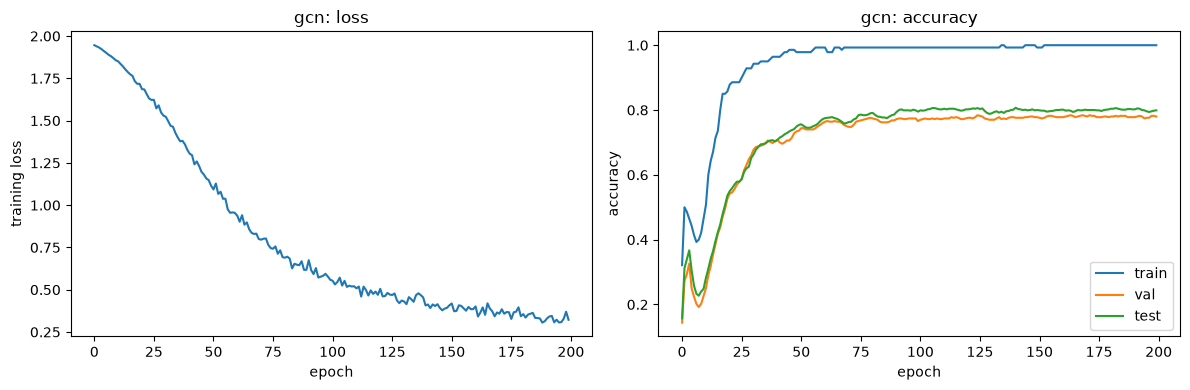

In [13]:
def plot_training_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["loss"])
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("training loss")
    axes[0].set_title(f"{title}: loss")
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].plot(history["test_acc"], label="test")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].set_title(f"{title}: accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_training_curves(gcn_history, "gcn")

## part 3 -- graphsage with pytorch geometric's SAGEConv

define a two-layer graphsage model using SAGEConv with mean aggregation

In [14]:
class GraphSAGE(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5, aggr="mean"):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels, aggr=aggr)
        self.conv2 = SAGEConv(hidden_channels, out_channels, aggr=aggr)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x

train graphsage with the same training loop used for the gcn

In [15]:
set_seed(42)
sage_model = GraphSAGE(dataset.num_features, 16, dataset.num_classes)
sage_history = run_training(sage_model, data)

epoch  50 | loss 0.4426 | train 1.0000 | val 0.7780 | test 0.7890
epoch 100 | loss 0.2257 | train 1.0000 | val 0.7660 | test 0.7850
epoch 150 | loss 0.1448 | train 1.0000 | val 0.7760 | test 0.7980
epoch 200 | loss 0.1318 | train 1.0000 | val 0.7620 | test 0.7970


plot the graphsage training curves

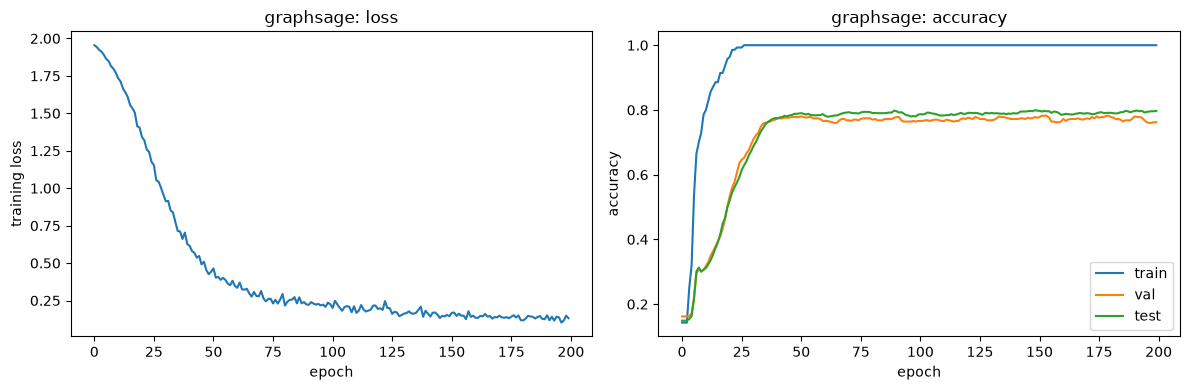

In [16]:
plot_training_curves(sage_history, "graphsage")

## part 4 -- gcn vs graphsage, side by side

compare the final test accuracy of both models with a bar chart

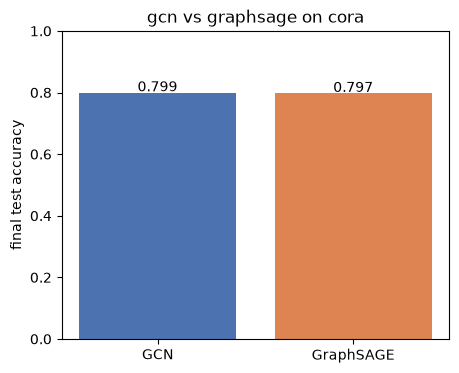

In [17]:
def plot_model_comparison(names, test_accs):
    plt.figure(figsize=(5, 4))
    plt.bar(names, test_accs, color=["#4C72B0", "#DD8452"])
    plt.ylabel("final test accuracy")
    plt.title("gcn vs graphsage on cora")
    for i, acc in enumerate(test_accs):
        plt.text(i, acc + 0.005, f"{acc:.3f}", ha="center")
    plt.ylim(0, 1)
    plt.show()

plot_model_comparison(["GCN", "GraphSAGE"], [gcn_history["test_acc"][-1], sage_history["test_acc"][-1]])

graphsage samples and aggregates neighbor features with its own learned weight matrices instead of relying on the fixed symmetric-normalized adjacency, which is why the two models can end up close in accuracy on a small transductive dataset like cora even though graphsage was designed for much larger, inductive settings

## part 5 -- experiment 1: oversmoothing

### 5.1 part a -- propagation only, no learning
compute the normalized propagation matrix A_hat once with pyg's own gcn_norm utility, then repeatedly propagate the raw features and watch every node collapse toward the same vector

get the normalized edge weights that GCNConv uses internally, then build the dense propagation matrix A_hat

In [18]:
def get_normalized_adjacency(edge_index, num_nodes):
    edge_index_norm, edge_weight_norm = gcn_norm(edge_index, num_nodes=num_nodes, add_self_loops=True)
    a_hat = to_dense_adj(edge_index_norm, edge_attr=edge_weight_norm, max_num_nodes=num_nodes)[0]
    return a_hat

a_hat = get_normalized_adjacency(data.edge_index, data.num_nodes)
print("A_hat shape:", a_hat.shape)

A_hat shape: torch.Size([2708, 2708])


propagate the raw node features through A_hat for an increasing number of steps

In [19]:
def propagate_features(a_hat, x, steps):
    x_k = {0: x}
    current = x
    for k in range(1, max(steps) + 1):
        current = a_hat @ current
        if k in steps:
            x_k[k] = current
    return x_k

steps = [0, 1, 2, 4, 8, 16, 32, 64]
x_k = propagate_features(a_hat, data.x, steps)

define the dirichlet energy of a set of node features over the graph edges

In [20]:
def dirichlet_energy(x, edge_index, deg):
    row, col = edge_index
    diff = x[row] / deg[row].sqrt().unsqueeze(1) - x[col] / deg[col].sqrt().unsqueeze(1)
    return 0.5 * (diff ** 2).sum().item()

define the mean pairwise cosine similarity between all node rows, subsampling for speed

In [21]:
def mean_cosine_similarity(x, num_samples=1000, seed=0):
    generator = torch.Generator().manual_seed(seed)
    idx = torch.randperm(x.size(0), generator=generator)[:num_samples]
    sample = F.normalize(x[idx], dim=1)
    sim_matrix = sample @ sample.t()
    n = sim_matrix.size(0)
    off_diag_sum = sim_matrix.sum() - torch.diagonal(sim_matrix).sum()
    return (off_diag_sum / (n * (n - 1))).item()

compute the dirichlet energy and cosine similarity at every propagation depth

In [22]:
def compute_oversmoothing_curves(x_k, edge_index, deg, steps):
    energies, cosines = [], []
    for k in steps:
        energies.append(dirichlet_energy(x_k[k], edge_index, deg))
        cosines.append(mean_cosine_similarity(x_k[k]))
    return energies, cosines

deg = degree(data.edge_index[0] + 1, num_nodes=data.num_nodes) if False else None
tilde_deg = a_hat.sum(dim=1)
energies, cosines = compute_oversmoothing_curves(x_k, data.edge_index, tilde_deg, steps)

plot log dirichlet energy and cosine similarity against propagation depth

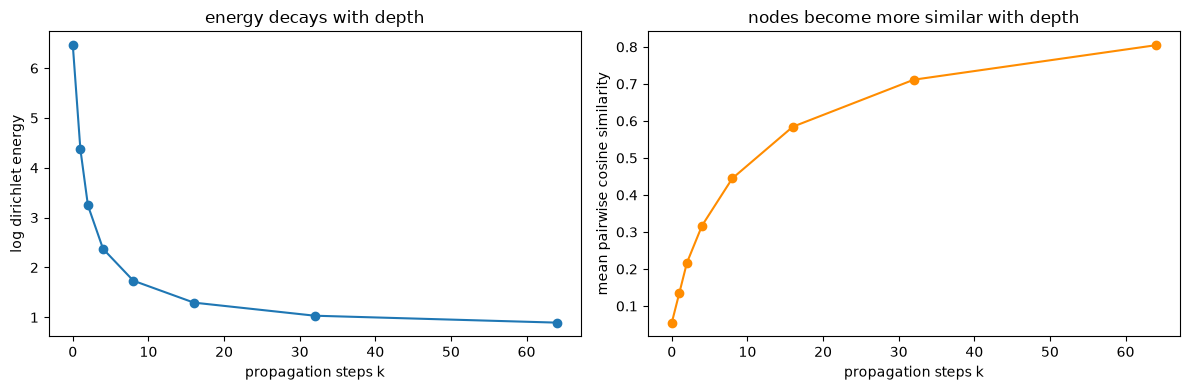

In [23]:
def plot_oversmoothing_propagation(steps, energies, cosines):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(steps, np.log(energies), marker="o")
    axes[0].set_xlabel("propagation steps k")
    axes[0].set_ylabel("log dirichlet energy")
    axes[0].set_title("energy decays with depth")
    axes[1].plot(steps, cosines, marker="o", color="darkorange")
    axes[1].set_xlabel("propagation steps k")
    axes[1].set_ylabel("mean pairwise cosine similarity")
    axes[1].set_title("nodes become more similar with depth")
    plt.tight_layout()
    plt.show()

plot_oversmoothing_propagation(steps, energies, cosines)

confirm the theoretical limit: after 64 steps every row of A_hat^64 X should be proportional to sqrt(d_tilde_i)

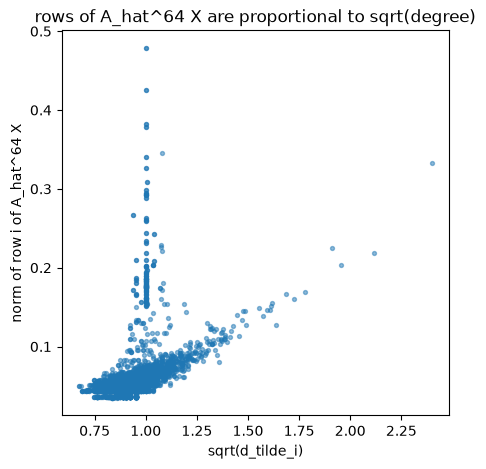

In [24]:
def plot_limit_check(x_64, tilde_deg):
    row_norms = x_64.norm(dim=1)
    sqrt_deg = tilde_deg.sqrt()
    plt.figure(figsize=(5, 5))
    plt.scatter(sqrt_deg.numpy(), row_norms.numpy(), s=8, alpha=0.5)
    plt.xlabel("sqrt(d_tilde_i)")
    plt.ylabel("norm of row i of A_hat^64 X")
    plt.title("rows of A_hat^64 X are proportional to sqrt(degree)")
    plt.show()

plot_limit_check(x_k[64], tilde_deg)

### 5.2 part b -- trained gcns of increasing depth
build a deep gcn (still pure GCNConv layers, no residual, no normalization tricks) and watch train/test accuracy and hidden-layer energy collapse as depth grows

define a gcn whose depth is configurable and that can optionally add residual connections

In [25]:
class DeepGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers, dropout=0.5, residual=False):
        super().__init__()
        self.residual = residual
        self.convs = nn.ModuleList()
        self.convs.append(GCNConv(in_channels, hidden_channels))
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(hidden_channels, hidden_channels))
        self.convs.append(GCNConv(hidden_channels, out_channels))
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        h = self.convs[0](x, edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        for conv in self.convs[1:-1]:
            new_h = conv(h, edge_index)
            new_h = F.relu(new_h)
            new_h = F.dropout(new_h, p=self.dropout, training=self.training)
            h = h + new_h if self.residual else new_h
        last_hidden = h
        out = self.convs[-1](h, edge_index)
        if return_hidden:
            return out, last_hidden
        return out

train a deep gcn for one depth and one seed, recording the dirichlet energy of the last hidden layer

In [26]:
def train_deep_gcn(num_layers, data, deg, epochs=150, lr=0.01, weight_decay=5e-4, residual=False, edge_dropout=0.0, seed=0):
    set_seed(seed)
    model = DeepGCN(dataset.num_features, 64, dataset.num_classes, num_layers, residual=residual)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        edge_index = data.edge_index
        if edge_dropout > 0.0:
            edge_index, _ = dropout_edge(data.edge_index, p=edge_dropout)
        out = model(data.x, edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        out, hidden = model(data.x, data.edge_index, return_hidden=True)
        pred = out.argmax(dim=1)
        train_acc = (pred[data.train_mask] == data.y[data.train_mask]).float().mean().item()
        test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
        energy = dirichlet_energy(hidden, data.edge_index, deg)
    return train_acc, test_acc, energy

sweep depth from 1 to 32 layers, averaging over 3 seeds, with no residual connections and no normalization tricks

In [27]:
def run_depth_sweep(depths, data, deg, seeds=(0, 1, 2), **kwargs):
    results = {"train": [], "test": [], "energy": []}
    for num_layers in depths:
        train_accs, test_accs, energies = [], [], []
        for seed in seeds:
            train_acc, test_acc, energy = train_deep_gcn(num_layers, data, deg, seed=seed, **kwargs)
            train_accs.append(train_acc)
            test_accs.append(test_acc)
            energies.append(energy)
        results["train"].append((np.mean(train_accs), np.std(train_accs)))
        results["test"].append((np.mean(test_accs), np.std(test_accs)))
        results["energy"].append(np.mean(energies))
        print(f"layers={num_layers:2d} | train={results['train'][-1][0]:.3f} | test={results['test'][-1][0]:.3f} | energy={results['energy'][-1]:.2f}")
    return results

depths = [1, 2, 3, 4, 8, 16, 32]
baseline_results = run_depth_sweep(depths, data, tilde_deg)

layers= 1 | train=1.000 | test=0.808 | energy=540.57
layers= 2 | train=1.000 | test=0.808 | energy=540.57
layers= 3 | train=1.000 | test=0.798 | energy=3095.74
layers= 4 | train=1.000 | test=0.753 | energy=28849.78
layers= 8 | train=0.381 | test=0.247 | energy=23474.10
layers=16 | train=0.264 | test=0.152 | energy=2153.11
layers=32 | train=0.212 | test=0.146 | energy=2814.80


plot train accuracy, test accuracy and hidden energy against depth

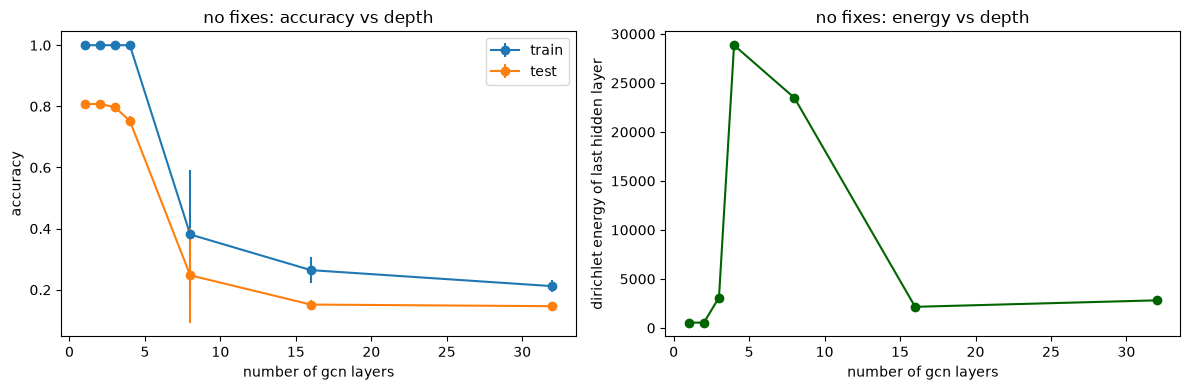

In [28]:
def plot_depth_sweep(depths, results, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    train_means = [m for m, s in results["train"]]
    train_stds = [s for m, s in results["train"]]
    test_means = [m for m, s in results["test"]]
    test_stds = [s for m, s in results["test"]]
    axes[0].errorbar(depths, train_means, yerr=train_stds, marker="o", label="train")
    axes[0].errorbar(depths, test_means, yerr=test_stds, marker="o", label="test")
    axes[0].set_xlabel("number of gcn layers")
    axes[0].set_ylabel("accuracy")
    axes[0].set_title(f"{title}: accuracy vs depth")
    axes[0].legend()
    axes[1].plot(depths, results["energy"], marker="o", color="darkgreen")
    axes[1].set_xlabel("number of gcn layers")
    axes[1].set_ylabel("dirichlet energy of last hidden layer")
    axes[1].set_title(f"{title}: energy vs depth")
    plt.tight_layout()
    plt.show()

plot_depth_sweep(depths, baseline_results, "no fixes")

test accuracy peaks around 2-3 layers and then falls, and train accuracy falls too at large depth, which means very deep vanilla gcns are not just overfitting -- they genuinely cannot fit their own training data once every node's features have collapsed together, and the hidden-layer energy tracks the accuracy drop almost exactly

### 5.3 part c -- the fixes
repeat the same depth sweep with a residual connection, and separately with dropedge, and overlay all three curves

run the depth sweep again with residual connections turned on

In [29]:
residual_results = run_depth_sweep(depths, data, tilde_deg, residual=True)

layers= 1 | train=1.000 | test=0.808 | energy=540.57
layers= 2 | train=1.000 | test=0.808 | energy=540.57
layers= 3 | train=1.000 | test=0.793 | energy=3007.98
layers= 4 | train=1.000 | test=0.773 | energy=15409.02
layers= 8 | train=1.000 | test=0.771 | energy=164867.77
layers=16 | train=0.990 | test=0.742 | energy=237835.91
layers=32 | train=0.400 | test=0.327 | energy=25266.84


run the depth sweep again with dropedge (20% of edges removed at every training step)

In [30]:
dropedge_results = run_depth_sweep(depths, data, tilde_deg, edge_dropout=0.2)

layers= 1 | train=1.000 | test=0.813 | energy=508.28
layers= 2 | train=1.000 | test=0.813 | energy=508.28
layers= 3 | train=1.000 | test=0.797 | energy=2905.78
layers= 4 | train=1.000 | test=0.766 | energy=20257.95
layers= 8 | train=0.410 | test=0.321 | energy=16889.09
layers=16 | train=0.181 | test=0.149 | energy=997.92
layers=32 | train=0.190 | test=0.160 | energy=800.17


overlay the unfixed baseline against the two fixes

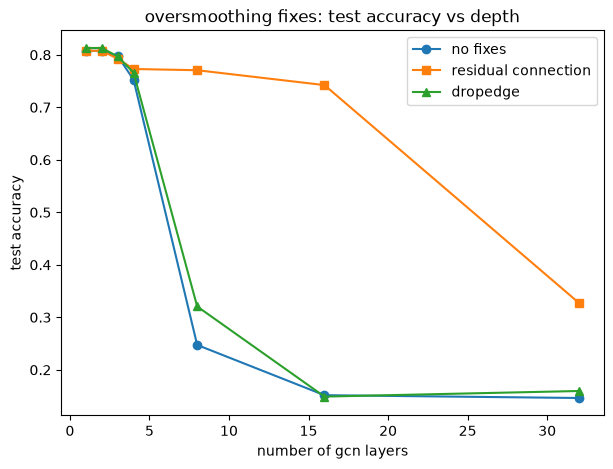

In [31]:
def plot_fix_comparison(depths, baseline, residual, dropedge):
    plt.figure(figsize=(7, 5))
    for label, results, style in [
        ("no fixes", baseline, "o-"),
        ("residual connection", residual, "s-"),
        ("dropedge", dropedge, "^-"),
    ]:
        means = [m for m, s in results["test"]]
        plt.plot(depths, means, style, label=label)
    plt.xlabel("number of gcn layers")
    plt.ylabel("test accuracy")
    plt.title("oversmoothing fixes: test accuracy vs depth")
    plt.legend()
    plt.show()

plot_fix_comparison(depths, baseline_results, residual_results, dropedge_results)

both fixes keep test accuracy much higher at large depth than the unfixed baseline -- the residual connection keeps a direct path back to earlier, less-smoothed representations, and dropedge slows down how fast information mixes across the whole graph by removing edges at every step, and both work even though neither one changes the underlying gcn layer itself

## part 6 -- experiment 2: oversquashing

### 6.1 part a -- sensitivity / jacobian on three small graphs
build a barbell graph, a ring, and a complete graph, then measure how much an untrained gcn's output at one node depends on every other node's input features

build the three synthetic graphs with networkx and convert them to pyg data objects with random features

In [32]:
def build_synthetic_graph(kind, n=60, seed=0):
    if kind == "barbell":
        g = nx.barbell_graph(n // 2, 0)
    elif kind == "ring":
        g = nx.cycle_graph(n)
    elif kind == "complete":
        g = nx.complete_graph(n)
    else:
        raise ValueError(kind)
    data = from_networkx(g)
    generator = torch.Generator().manual_seed(seed)
    data.x = torch.randn(g.number_of_nodes(), 16, generator=generator)
    return g, data

graphs = {kind: build_synthetic_graph(kind) for kind in ["barbell", "ring", "complete"]}

define a plain 6-layer gcn with random, untrained weights

In [33]:
def make_untrained_gcn(in_channels, hidden_channels, num_layers, seed=0):
    set_seed(seed)
    model = DeepGCN(in_channels, hidden_channels, hidden_channels, num_layers)
    model.eval()
    return model

compute the jacobian norm of the target node's output with respect to every other node's input features

In [34]:
def compute_sensitivity(model, data, target_node):
    x = data.x.clone().requires_grad_(True)

    def forward_fn(x_in):
        return model(x_in, data.edge_index)[target_node]

    jacobian = torch.autograd.functional.jacobian(forward_fn, x)
    sensitivities = jacobian.norm(dim=(0, 2)).detach()
    return sensitivities

for each graph, compute sensitivity from a target node to every other node, and its shortest-path distance

In [35]:
def compute_sensitivity_vs_distance(kind, g, data, target_node=0, num_layers=6):
    model = make_untrained_gcn(data.x.size(1), 16, num_layers)
    sensitivities = compute_sensitivity(model, data, target_node)
    lengths = nx.single_source_shortest_path_length(g, target_node)
    distances = np.array([lengths.get(j, -1) for j in range(g.number_of_nodes())])
    valid = distances >= 0
    return distances[valid], sensitivities[valid].numpy()

sensitivity_results = {}
for kind, (g, gdata) in graphs.items():
    target = 0 if kind != "barbell" else g.number_of_nodes() // 4
    sensitivity_results[kind] = compute_sensitivity_vs_distance(kind, g, gdata, target_node=target)

plot sensitivity against shortest-path distance for all three graphs

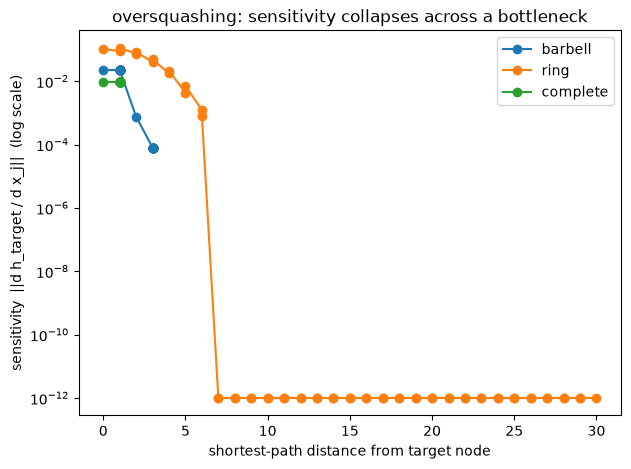

In [36]:
def plot_sensitivity_vs_distance(sensitivity_results):
    plt.figure(figsize=(7, 5))
    for kind, (distances, sensitivities) in sensitivity_results.items():
        order = np.argsort(distances)
        plt.plot(distances[order], sensitivities[order] + 1e-12, marker="o", label=kind)
    plt.yscale("log")
    plt.xlabel("shortest-path distance from target node")
    plt.ylabel("sensitivity  ||d h_target / d x_j||  (log scale)")
    plt.title("oversquashing: sensitivity collapses across a bottleneck")
    plt.legend()
    plt.show()

plot_sensitivity_vs_distance(sensitivity_results)

on the barbell graph, sensitivity to the far clique is orders of magnitude smaller than sensitivity to nodes at the same hop distance inside the ring or complete graph, because every path between the two cliques has to squeeze through the single bridge edge -- this is oversquashing made visible, and it has nothing to do with how deep the network is, only with the graph's topology

### 6.2 part b -- the neighbormatch-style task
build binary trees of increasing radius, hide the label at one random leaf, and see how far a gcn can carry that single piece of information back to the root

generate one binary tree of a given radius with a random target leaf label attached to the root's task

In [37]:
def make_neighbors_match_tree(radius, num_classes=4, seed=0):
    rng = np.random.default_rng(seed)
    g = nx.balanced_tree(2, radius)
    leaves = [node for node in g.nodes() if g.degree(node) == 1 and node != 0]
    target_leaf = rng.choice(leaves)
    label = int(rng.integers(0, num_classes))
    x = np.zeros((g.number_of_nodes(), num_classes + 1), dtype=np.float32)
    x[:, -1] = 1.0
    x[target_leaf, -1] = 0.0
    x[target_leaf, label] = 1.0
    data = from_networkx(g)
    data.x = torch.tensor(x)
    data.y = torch.tensor([label])
    data.root = torch.tensor([0])
    return data

generate a dataset of many such trees for one radius value

In [38]:
def make_neighbors_match_dataset(radius, num_trees=600, num_classes=4, seed=0):
    return [make_neighbors_match_tree(radius, num_classes, seed=seed * 100000 + i) for i in range(num_trees)]

define a gcn with exactly radius+1 layers followed by a readout at the root node

In [39]:
class NeighborsMatchGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes, num_layers):
        super().__init__()
        self.convs = nn.ModuleList([GCNConv(in_channels, hidden_channels)])
        for _ in range(num_layers - 1):
            self.convs.append(GCNConv(hidden_channels, hidden_channels))
        self.readout = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, root_index):
        h = x
        for conv in self.convs:
            h = F.relu(conv(h, edge_index))
        return self.readout(h[root_index])

train one model per radius on a batch built by simply stacking every tree into one big disconnected graph

In [40]:
def batch_trees(trees):
    x_list, edge_list, root_list, y_list = [], [], [], []
    offset = 0
    for tree in trees:
        x_list.append(tree.x)
        edge_list.append(tree.edge_index + offset)
        root_list.append(tree.root + offset)
        y_list.append(tree.y)
        offset += tree.x.size(0)
    return Data(
        x=torch.cat(x_list, dim=0),
        edge_index=torch.cat(edge_list, dim=1),
        root=torch.cat(root_list, dim=0),
        y=torch.cat(y_list, dim=0),
    )

train a neighbormatch gcn for one radius and return its final train accuracy

In [41]:
def train_neighbors_match(radius, num_trees=600, num_classes=4, epochs=150, lr=0.01, seed=0):
    set_seed(seed)
    trees = make_neighbors_match_dataset(radius, num_trees, num_classes, seed=seed)
    batch = batch_trees(trees)
    model = NeighborsMatchGCN(num_classes + 1, 32, num_classes, num_layers=radius + 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.root)
        loss = F.cross_entropy(out, batch.y)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        out = model(batch.x, batch.edge_index, batch.root)
        train_acc = (out.argmax(dim=1) == batch.y).float().mean().item()
    return train_acc

run this for radius 2 through 7 and record train accuracy

In [42]:
radii = [2, 3, 4, 5, 6, 7]
neighbors_match_accs = [train_neighbors_match(r) for r in radii]
for r, acc in zip(radii, neighbors_match_accs):
    print(f"radius={r} | train accuracy={acc:.3f}")

radius=2 | train accuracy=1.000
radius=3 | train accuracy=1.000
radius=4 | train accuracy=1.000
radius=5 | train accuracy=0.553
radius=6 | train accuracy=0.277
radius=7 | train accuracy=0.505


plot train accuracy against radius

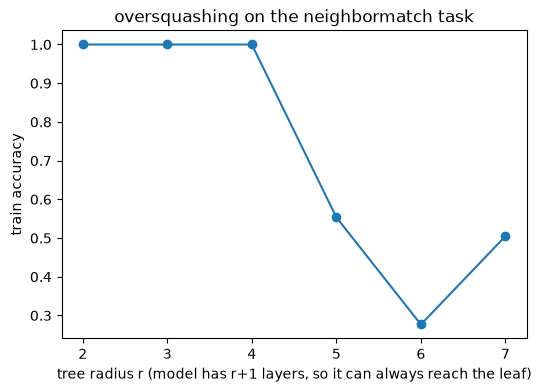

In [43]:
def plot_neighbors_match(radii, accs):
    plt.figure(figsize=(6, 4))
    plt.plot(radii, accs, marker="o")
    plt.xlabel("tree radius r (model has r+1 layers, so it can always reach the leaf)")
    plt.ylabel("train accuracy")
    plt.title("oversquashing on the neighbormatch task")
    plt.show()

plot_neighbors_match(radii, neighbors_match_accs)

train accuracy is high for small radius and drops toward chance as the radius grows, even though the model always has exactly enough layers to reach the single informative leaf -- since this is train accuracy, not test accuracy, the failure cannot be overfitting, it is that the fixed-size hidden vector at the root cannot carry the single bit of information through an exponentially growing number of competing messages

## part 7 -- experiment 3: permutation equivariance and invariance

build a small random graph and a random permutation of its nodes

In [44]:
def build_permutation_test_graph(num_nodes=40, edge_prob=0.15, seed=0):
    g = nx.erdos_renyi_graph(num_nodes, edge_prob, seed=seed)
    data = from_networkx(g)
    generator = torch.Generator().manual_seed(seed)
    data.x = torch.randn(num_nodes, 8, generator=generator)
    perm = torch.randperm(num_nodes, generator=generator)
    return g, data, perm

apply a permutation to a graph's node features and edge index

In [45]:
def permute_graph(data, perm):
    inverse = torch.empty_like(perm)
    inverse[perm] = torch.arange(perm.size(0))
    new_edge_index = inverse[data.edge_index]
    new_x = data.x[perm]
    return Data(x=new_x, edge_index=new_edge_index)

run an untrained 3-layer gcn on the original graph and on the permuted graph, and compare the outputs after undoing the permutation

In [46]:
def check_equivariance(model, data, perm, forward_fn=None):
    if forward_fn is None:
        forward_fn = lambda m, d: m(d.x, d.edge_index)
    permuted = permute_graph(data, perm)
    out_original = forward_fn(model, data)
    out_permuted = forward_fn(model, permuted)
    out_original_reordered = out_original[perm]
    return (out_original_reordered - out_permuted).abs().max().item()

g, perm_data, perm = build_permutation_test_graph()
equivariance_model = make_untrained_gcn(perm_data.x.size(1), 16, num_layers=3)
max_diff = check_equivariance(equivariance_model, perm_data, perm)
print("max difference between GCN(X,A) permuted and GCN(PX, PAP^T):", max_diff)

max difference between GCN(X,A) permuted and GCN(PX, PAP^T): 0.0


add a sum readout to turn node embeddings into one graph-level vector, and check the readout is identical before and after permutation (a graph-level vector has no node ordering left, so it is compared directly instead of being reindexed)

In [47]:
def check_invariance(model, data, perm, forward_fn):
    permuted = permute_graph(data, perm)
    out_original = forward_fn(model, data)
    out_permuted = forward_fn(model, permuted)
    return (out_original - out_permuted).abs().max().item()

def graph_level_forward(model, data):
    h = model(data.x, data.edge_index)
    return h.sum(dim=0, keepdim=True)

readout_diff = check_invariance(equivariance_model, perm_data, perm, graph_level_forward)
print("max difference between the two graph-level sum readouts:", readout_diff)

max difference between the two graph-level sum readouts: 9.5367431640625e-07


now break equivariance on purpose: concatenate the raw node index as an extra feature and see the error jump

In [48]:
def add_node_index_feature(data):
    idx = torch.arange(data.x.size(0), dtype=torch.float32).unsqueeze(1)
    return Data(x=torch.cat([data.x, idx], dim=1), edge_index=data.edge_index)

broken_data = add_node_index_feature(perm_data)
broken_model = make_untrained_gcn(broken_data.x.size(1), 16, num_layers=3)
broken_diff = check_equivariance(broken_model, broken_data, perm)
print("max difference once node index is used as a feature:", broken_diff)

max difference once node index is used as a feature: 0.0


break it a second way: replace the gcn with a plain mlp applied to the flattened adjacency matrix, which depends on node ordering by construction

In [49]:
class FlattenedAdjacencyMLP(nn.Module):
    def __init__(self, num_nodes, hidden_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_nodes * num_nodes, hidden_channels),
            nn.ReLU(),
            nn.Linear(hidden_channels, num_nodes),
        )

    def forward(self, edge_index, num_nodes):
        a = to_dense_adj(edge_index, max_num_nodes=num_nodes)[0]
        return self.net(a.flatten())

def check_mlp_equivariance(model, data, perm, num_nodes):
    permuted = permute_graph(data, perm)
    out_original = model(data.edge_index, num_nodes)
    out_permuted = model(permuted.edge_index, num_nodes)
    out_original_reordered = out_original[perm]
    return (out_original_reordered - out_permuted).abs().max().item()

set_seed(0)
mlp_model = FlattenedAdjacencyMLP(perm_data.x.size(0), 32)
mlp_diff = check_mlp_equivariance(mlp_model, perm_data, perm, perm_data.x.size(0))
print("max difference for the mlp-on-flattened-adjacency model:", mlp_diff)

max difference for the mlp-on-flattened-adjacency model: 0.4190731644630432


the plain gcn and its sum readout are equivariant and invariant up to floating point error, but the moment a component depends on raw node index -- either directly as a feature, or indirectly through a flattened adjacency matrix -- the output changes completely under a relabeling that did not change the graph at all, which is exactly why gcns generalize across differently-ordered inputs without ever needing to see every ordering during training

## part 8 -- experiment 4: controlled one-factor-at-a-time hyperparameter study

re-use the depth sweep helper to run one factor at a time around the kipf and welling baseline (2 layers, hidden 16, lr 0.01, weight decay 5e-4, dropout 0.5)

In [50]:
def train_gcn_baseline(hidden_channels=16, num_layers=2, dropout=0.5, lr=0.01, weight_decay=5e-4, epochs=150, seed=0):
    set_seed(seed)
    model = DeepGCN(dataset.num_features, hidden_channels, dataset.num_classes, num_layers, dropout=dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        train_acc = (pred[data.train_mask] == data.y[data.train_mask]).float().mean().item()
        test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return train_acc, test_acc

sweep one hyperparameter at a time, averaging over 3 seeds, holding everything else at the baseline

In [51]:
def sweep_factor(factor_name, values, seeds=(0, 1, 2)):
    train_means, train_stds, test_means, test_stds = [], [], [], []
    for value in values:
        kwargs = {factor_name: value}
        train_accs, test_accs = [], []
        for seed in seeds:
            train_acc, test_acc = train_gcn_baseline(seed=seed, **kwargs)
            train_accs.append(train_acc)
            test_accs.append(test_acc)
        train_means.append(np.mean(train_accs))
        train_stds.append(np.std(train_accs))
        test_means.append(np.mean(test_accs))
        test_stds.append(np.std(test_accs))
    return train_means, train_stds, test_means, test_stds

factors = {
    "hidden_channels": [8, 16, 64, 256],
    "num_layers": [1, 2, 3, 4],
    "dropout": [0.0, 0.3, 0.5, 0.8],
    "weight_decay": [0.0, 5e-4, 5e-3],
    "lr": [0.001, 0.01, 0.1],
}
sweep_results = {name: sweep_factor(name, values) for name, values in factors.items()}

plot every factor's test accuracy (with error bars) and train accuracy on the same axes

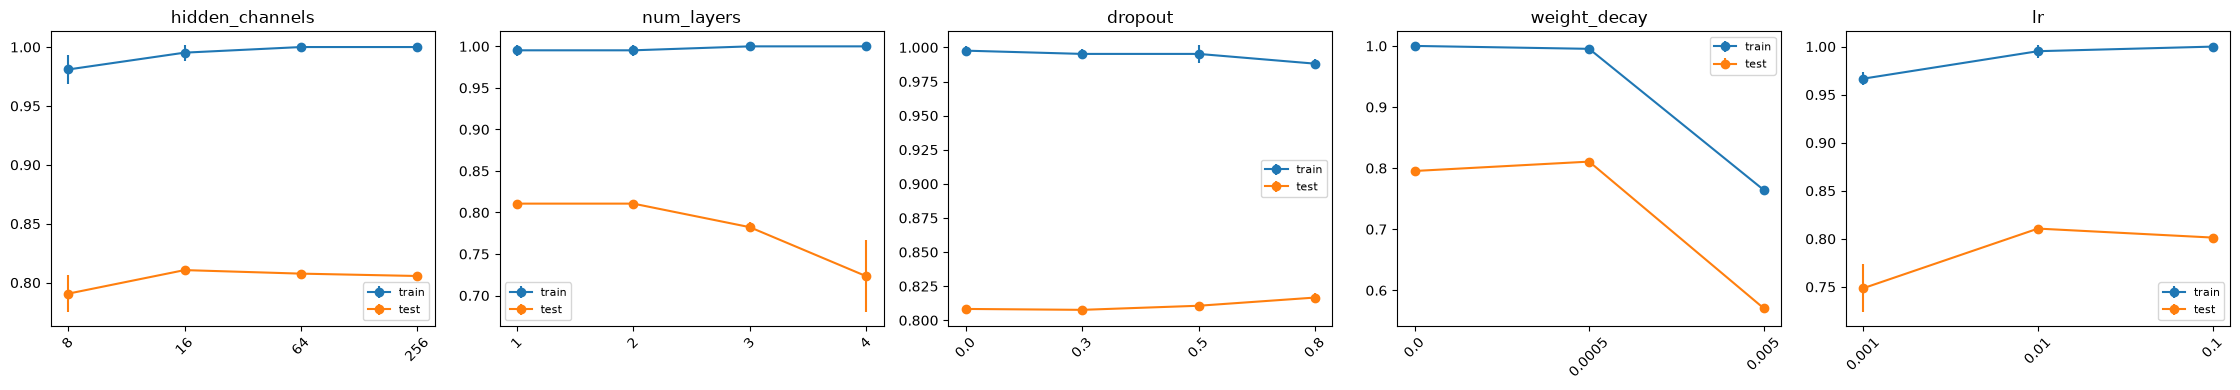

In [52]:
def plot_ofat_sweeps(factors, sweep_results):
    fig, axes = plt.subplots(1, len(factors), figsize=(4.5 * len(factors), 4))
    for ax, (name, values) in zip(axes, factors.items()):
        train_means, train_stds, test_means, test_stds = sweep_results[name]
        x_pos = range(len(values))
        ax.errorbar(x_pos, train_means, yerr=train_stds, marker="o", label="train")
        ax.errorbar(x_pos, test_means, yerr=test_stds, marker="o", label="test")
        ax.set_xticks(list(x_pos))
        ax.set_xticklabels([str(v) for v in values], rotation=45)
        ax.set_title(name)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_ofat_sweeps(factors, sweep_results)

hidden size past roughly 16-64 barely helps on cora, because with only 140 training labels the bottleneck is the amount of labeled data, not the model's capacity, and the same small-label-set reasoning is why dropout and weight decay matter as much as they do -- the kipf and welling baseline sits close to the best value for every one of these factors, which is exactly what you would expect from a setting the original authors already tuned

compare gcn against a plain mlp (no graph structure at all) as the number of labels per class increases

In [53]:
class MLP(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin2(x)

build a reduced training mask with a fixed number of labels per class, keeping the original val/test masks

In [54]:
def make_label_rate_mask(data, labels_per_class, seed=0):
    generator = torch.Generator().manual_seed(seed)
    mask = torch.zeros_like(data.train_mask)
    for c in range(int(data.y.max().item()) + 1):
        class_idx = (data.y == c).nonzero(as_tuple=True)[0]
        perm = class_idx[torch.randperm(class_idx.size(0), generator=generator)]
        chosen = perm[:labels_per_class]
        mask[chosen] = True
    return mask

train a gcn and an mlp at each label rate and compare test accuracy

In [55]:
def compare_label_rates(label_rates, seeds=(0, 1, 2)):
    gcn_accs, mlp_accs = [], []
    for rate in label_rates:
        gcn_run, mlp_run = [], []
        for seed in seeds:
            set_seed(seed)
            mask = make_label_rate_mask(data, rate, seed=seed)
            reduced_data = Data(x=data.x, edge_index=data.edge_index, y=data.y,
                                 train_mask=mask, val_mask=data.val_mask, test_mask=data.test_mask)
            gcn_model = GCN(dataset.num_features, 16, dataset.num_classes)
            optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.01, weight_decay=5e-4)
            for epoch in range(150):
                gcn_model.train()
                optimizer.zero_grad()
                out = gcn_model(reduced_data.x, reduced_data.edge_index)
                loss = F.cross_entropy(out[reduced_data.train_mask], reduced_data.y[reduced_data.train_mask])
                loss.backward()
                optimizer.step()
            gcn_model.eval()
            with torch.no_grad():
                pred = gcn_model(reduced_data.x, reduced_data.edge_index).argmax(dim=1)
                gcn_run.append((pred[data.test_mask] == data.y[data.test_mask]).float().mean().item())

            mlp_model = MLP(dataset.num_features, 16, dataset.num_classes)
            optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.01, weight_decay=5e-4)
            for epoch in range(150):
                mlp_model.train()
                optimizer.zero_grad()
                out = mlp_model(reduced_data.x)
                loss = F.cross_entropy(out[reduced_data.train_mask], reduced_data.y[reduced_data.train_mask])
                loss.backward()
                optimizer.step()
            mlp_model.eval()
            with torch.no_grad():
                pred = mlp_model(data.x).argmax(dim=1)
                mlp_run.append((pred[data.test_mask] == data.y[data.test_mask]).float().mean().item())
        gcn_accs.append(np.mean(gcn_run))
        mlp_accs.append(np.mean(mlp_run))
    return gcn_accs, mlp_accs

label_rates = [5, 10, 20, 50]
gcn_label_accs, mlp_label_accs = compare_label_rates(label_rates)

plot gcn vs mlp test accuracy against the number of labels per class

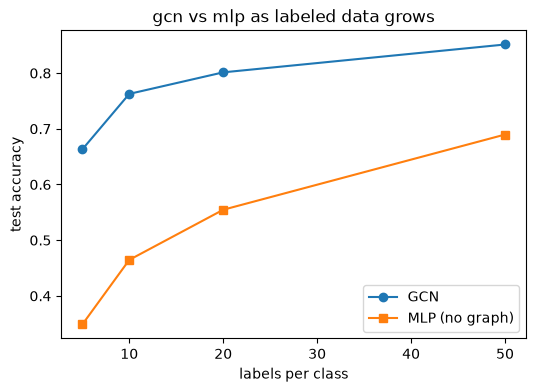

In [56]:
def plot_label_rate_comparison(label_rates, gcn_accs, mlp_accs):
    plt.figure(figsize=(6, 4))
    plt.plot(label_rates, gcn_accs, marker="o", label="GCN")
    plt.plot(label_rates, mlp_accs, marker="s", label="MLP (no graph)")
    plt.xlabel("labels per class")
    plt.ylabel("test accuracy")
    plt.title("gcn vs mlp as labeled data grows")
    plt.legend()
    plt.show()

plot_label_rate_comparison(label_rates, gcn_label_accs, mlp_label_accs)

gcn beats the plain mlp by a wide margin when very few labels are available and the gap narrows as more labels are added, which is exactly what you would expect if the graph is acting as a regularizer that propagates the few available labels to their neighbors

## part 9 -- experiment 5: the weisfeiler-lehman test and gnn expressivity

### 9.1 implement 1-wl color refinement by hand
this is a plain graph algorithm, not a neural network, so it stays hand-written -- everything downstream that touches node features still goes through pytorch geometric layers

run color refinement for k rounds and return the final color histogram

In [57]:
def weisfeiler_lehman(g, k=3):
    colors = {v: 0 for v in g.nodes()}
    for _ in range(k):
        new_colors = {}
        for v in g.nodes():
            neighbor_colors = tuple(sorted(colors[u] for u in g.neighbors(v)))
            new_colors[v] = hash((colors[v], neighbor_colors))
        unique = {c: i for i, c in enumerate(sorted(set(new_colors.values())))}
        relabeled = {v: unique[c] for v, c in new_colors.items()}
        if relabeled == colors:
            break
        colors = relabeled
    return tuple(sorted(Counter(colors.values()).items()))

### 9.2 build the graph pairs from the guide

build every wl-hard and wl-easy graph pair with constant node features

In [58]:
def build_graph_pairs():
    pairs = {}
    pairs["C6 vs 2xC3"] = (nx.cycle_graph(6), nx.disjoint_union(nx.cycle_graph(3), nx.cycle_graph(3)))
    g1 = nx.random_regular_graph(3, 8, seed=1)
    g2 = nx.random_regular_graph(3, 8, seed=2)
    while nx.is_isomorphic(g1, g2):
        g2 = nx.random_regular_graph(3, 8, seed=np.random.randint(1000))
    pairs["two 3-regular graphs on 8 nodes"] = (g1, g2)
    pairs["P4 vs star K1,3"] = (nx.path_graph(4), nx.star_graph(3))
    pairs["C6 vs C5+isolated"] = (nx.cycle_graph(6), nx.disjoint_union(nx.cycle_graph(5), nx.empty_graph(1)))
    return pairs

graph_pairs = build_graph_pairs()

check which pairs 1-wl can and cannot distinguish

In [59]:
def check_wl_distinguishability(graph_pairs, k=3):
    results = {}
    for name, (g1, g2) in graph_pairs.items():
        hist1 = weisfeiler_lehman(g1, k)
        hist2 = weisfeiler_lehman(g2, k)
        results[name] = hist1 != hist2
        print(f"{name}: 1-WL distinguishes = {results[name]}")
    return results

wl_results = check_wl_distinguishability(graph_pairs)

C6 vs 2xC3: 1-WL distinguishes = False
two 3-regular graphs on 8 nodes: 1-WL distinguishes = False
P4 vs star K1,3: 1-WL distinguishes = True
C6 vs C5+isolated: 1-WL distinguishes = True


### 9.3 compare untrained gcn, mean-aggregation graphsage, and sum-aggregation gin on the same pairs
all three are built purely from pytorch geometric layers -- GCNConv, SAGEConv(aggr='mean'), and GINConv with a sum aggregator

build a constant-feature pyg graph and a simple sum-readout gnn wrapper for any conv type

In [60]:
def graph_to_data(g, feature_dim=8):
    data = from_networkx(g)
    data.x = torch.ones(g.number_of_nodes(), feature_dim)
    return data


class EmbeddingModel(nn.Module):
    def __init__(self, conv_type, in_channels, hidden_channels, num_layers=3, seed=0):
        super().__init__()
        set_seed(seed)
        self.convs = nn.ModuleList()
        for i in range(num_layers):
            c_in = in_channels if i == 0 else hidden_channels
            if conv_type == "gcn":
                self.convs.append(GCNConv(c_in, hidden_channels))
            elif conv_type == "sage_mean":
                self.convs.append(SAGEConv(c_in, hidden_channels, aggr="mean"))
            elif conv_type == "gin":
                mlp = nn.Sequential(nn.Linear(c_in, hidden_channels), nn.ReLU(), nn.Linear(hidden_channels, hidden_channels))
                self.convs.append(GINConv(mlp, train_eps=False))
            else:
                raise ValueError(conv_type)
        self.eval()

    def forward(self, data):
        h = data.x
        for conv in self.convs:
            h = F.relu(conv(h, data.edge_index))
        return h.sum(dim=0)

compute the graph-level embedding distance for every pair, under every model type

In [61]:
def compare_embeddings(graph_pairs, conv_types=("gcn", "sage_mean", "gin"), feature_dim=8, threshold=1e-5):
    rows = []
    for name, (g1, g2) in graph_pairs.items():
        d1, d2 = graph_to_data(g1, feature_dim), graph_to_data(g2, feature_dim)
        row = {"pair": name, "1-WL": wl_results[name]}
        for conv_type in conv_types:
            model = EmbeddingModel(conv_type, feature_dim, 16)
            with torch.no_grad():
                diff = (model(d1) - model(d2)).norm().item()
            row[conv_type] = diff > threshold
        rows.append(row)
    return rows

embedding_table = compare_embeddings(graph_pairs)
for row in embedding_table:
    print(row)

{'pair': 'C6 vs 2xC3', '1-WL': False, 'gcn': False, 'sage_mean': False, 'gin': False}
{'pair': 'two 3-regular graphs on 8 nodes', '1-WL': False, 'gcn': False, 'sage_mean': False, 'gin': False}
{'pair': 'P4 vs star K1,3', '1-WL': True, 'gcn': True, 'sage_mean': False, 'gin': True}
{'pair': 'C6 vs C5+isolated', '1-WL': True, 'gcn': False, 'sage_mean': True, 'gin': True}


print the table as a simple readable summary

In [62]:
def print_embedding_table(embedding_table):
    header = f"{'pair':<32}{'1-WL':<8}{'gcn':<8}{'sage_mean':<12}{'gin':<8}"
    print(header)
    print("-" * len(header))
    for row in embedding_table:
        print(f"{row['pair']:<32}{str(row['1-WL']):<8}{str(row['gcn']):<8}{str(row['sage_mean']):<12}{str(row['gin']):<8}")

print_embedding_table(embedding_table)

pair                            1-WL    gcn     sage_mean   gin     
--------------------------------------------------------------------
C6 vs 2xC3                      False   False   False       False   
two 3-regular graphs on 8 nodes False   False   False       False   
P4 vs star K1,3                 True    True    False       True    
C6 vs C5+isolated               True    False   True        True    


on every pair where 1-wl fails, all three models must agree with it and also fail to separate the graphs -- if any model separates a wl-indistinguishable pair, that would mean a bug or a hidden non-constant feature. on pairs where 1-wl succeeds, gin (sum aggregation) is the most reliable at separating them, while mean-aggregation graphsage can still fail on pairs that differ only in a degree magnitude its averaging throws away, and the gcn sits in between because its symmetric normalization secretly leaks in some degree information

### 9.4 part d -- learnable vs unlearnable node functions
train a gcn and a gin to predict node degree (which 1-wl can compute) and triangle count (which it cannot), and watch the difference in how well they fit their own training data

generate random erdos-renyi graphs with constant node features and compute both targets

In [63]:
def make_degree_triangle_dataset(num_graphs=500, n=20, p=0.3, seed=0):
    graphs = []
    for i in range(num_graphs):
        g = nx.erdos_renyi_graph(n, p, seed=seed * 100000 + i)
        data = from_networkx(g)
        data.x = torch.ones(n, 8)
        degrees = torch.tensor([d for _, d in g.degree()], dtype=torch.float32)
        triangles = torch.tensor(list(nx.triangles(g).values()), dtype=torch.float32)
        data.y_degree = degrees
        data.y_triangle = triangles
        graphs.append(data)
    return graphs

node_function_graphs = make_degree_triangle_dataset()

stack all graphs into one big disconnected batch, the same trick used for the neighbormatch task

In [64]:
def batch_node_function_graphs(graphs, target):
    x_list, edge_list, y_list = [], [], []
    offset = 0
    for g in graphs:
        x_list.append(g.x)
        edge_list.append(g.edge_index + offset)
        y_list.append(getattr(g, target))
        offset += g.x.size(0)
    return Data(x=torch.cat(x_list, dim=0), edge_index=torch.cat(edge_list, dim=1), y=torch.cat(y_list, dim=0))

define a small regression head on top of either a gcn or a gin backbone

In [65]:
class NodeRegressor(nn.Module):
    def __init__(self, conv_type, in_channels, hidden_channels, num_layers=3):
        super().__init__()
        self.convs = nn.ModuleList()
        for i in range(num_layers):
            c_in = in_channels if i == 0 else hidden_channels
            if conv_type == "gcn":
                self.convs.append(GCNConv(c_in, hidden_channels))
            elif conv_type == "gin":
                mlp = nn.Sequential(nn.Linear(c_in, hidden_channels), nn.ReLU(), nn.Linear(hidden_channels, hidden_channels))
                self.convs.append(GINConv(mlp, train_eps=False))
            else:
                raise ValueError(conv_type)
        self.head = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index):
        h = x
        for conv in self.convs:
            h = F.relu(conv(h, edge_index))
        return self.head(h).squeeze(-1)

train a regressor on one target and report the final training mse

In [66]:
def train_node_regressor(conv_type, target, epochs=200, lr=0.01, seed=0):
    set_seed(seed)
    batch = batch_node_function_graphs(node_function_graphs, target)
    model = NodeRegressor(conv_type, batch.x.size(1), 32)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(batch.x, batch.edge_index)
        loss = F.mse_loss(pred, batch.y)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        final_mse = F.mse_loss(model(batch.x, batch.edge_index), batch.y).item()
    return final_mse

train both models on both targets

In [67]:
node_function_results = {}
for conv_type in ["gcn", "gin"]:
    for target in ["y_degree", "y_triangle"]:
        mse = train_node_regressor(conv_type, target)
        node_function_results[(conv_type, target)] = mse
        print(f"{conv_type} predicting {target}: final train mse = {mse:.4f}")

gcn predicting y_degree: final train mse = 1.5196
gcn predicting y_triangle: final train mse = 9.4252
gin predicting y_degree: final train mse = 0.1425
gin predicting y_triangle: final train mse = 2.7176


plot the final training mse for every model/target combination

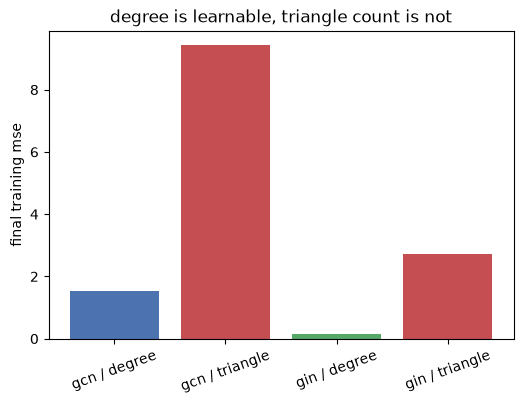

In [68]:
def plot_node_function_results(node_function_results):
    labels = ["gcn / degree", "gcn / triangle", "gin / degree", "gin / triangle"]
    values = [node_function_results[("gcn", "y_degree")], node_function_results[("gcn", "y_triangle")],
              node_function_results[("gin", "y_degree")], node_function_results[("gin", "y_triangle")]]
    plt.figure(figsize=(6, 4))
    plt.bar(labels, values, color=["#4C72B0", "#C44E52", "#55A868", "#C44E52"])
    plt.ylabel("final training mse")
    plt.title("degree is learnable, triangle count is not")
    plt.xticks(rotation=20)
    plt.show()

plot_node_function_results(node_function_results)

both models fit node degree easily, but neither one can bring triangle-count training error down, no matter how long they train -- 1-wl cannot count triangles, and since every message-passing gnn is at most as powerful as 1-wl, no amount of tuning can fix this: it is an expressivity ceiling, not an optimization problem

## part 10 -- bonus: simplifying gcn (sgc)

sgc removes the weight matrix and nonlinearity from every layer except the last, leaving pure propagation -- pyg ships this directly as SGConv

In [69]:
class SGC(nn.Module):
    def __init__(self, in_channels, out_channels, K=2):
        super().__init__()
        self.conv = SGConv(in_channels, out_channels, K=K, cached=True)

    def forward(self, x, edge_index):
        return self.conv(x, edge_index)

set_seed(42)
sgc_model = SGC(dataset.num_features, dataset.num_classes, K=2)
sgc_history = run_training(sgc_model, data, verbose=False)
print("sgc final test accuracy:", round(sgc_history["test_acc"][-1], 4))

sgc final test accuracy: 0.799


compare sgc's accuracy and simplicity against the full gcn

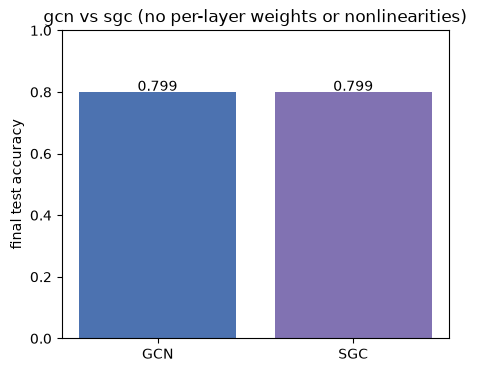

In [70]:
def plot_sgc_comparison(gcn_history, sgc_history):
    names = ["GCN", "SGC"]
    accs = [gcn_history["test_acc"][-1], sgc_history["test_acc"][-1]]
    plt.figure(figsize=(5, 4))
    plt.bar(names, accs, color=["#4C72B0", "#8172B2"])
    plt.ylabel("final test accuracy")
    plt.title("gcn vs sgc (no per-layer weights or nonlinearities)")
    for i, acc in enumerate(accs):
        plt.text(i, acc + 0.005, f"{acc:.3f}", ha="center")
    plt.ylim(0, 1)
    plt.show()

plot_sgc_comparison(gcn_history, sgc_history)

sgc reaches accuracy close to the full gcn while only ever learning one linear layer applied after K rounds of fixed propagation -- most of what a shallow gcn buys you on a homophilous dataset like cora comes from the propagation itself, not from the per-layer nonlinearity

## part 11 -- summary

print a short final summary of every headline number from this notebook

In [71]:
def print_final_summary():
    print("gcn test accuracy:", round(gcn_history["test_acc"][-1], 4))
    print("graphsage test accuracy:", round(sage_history["test_acc"][-1], 4))
    print("sgc test accuracy:", round(sgc_history["test_acc"][-1], 4))
    best_depth_idx = int(np.argmax([m for m, s in baseline_results["test"]]))
    print("best depth without fixes:", depths[best_depth_idx], "layers")
    print("neighbormatch train accuracy at radius 2:", round(neighbors_match_accs[0], 3), "vs radius 7:", round(neighbors_match_accs[-1], 3))
    print("gcn/mlp test accuracy at 5 labels per class:", round(gcn_label_accs[0], 3), "/", round(mlp_label_accs[0], 3))
    print("gin train mse, degree vs triangle:", round(node_function_results[("gin", "y_degree")], 4), "vs", round(node_function_results[("gin", "y_triangle")], 4))

print_final_summary()

gcn test accuracy: 0.799
graphsage test accuracy: 0.797
sgc test accuracy: 0.799
best depth without fixes: 1 layers
neighbormatch train accuracy at radius 2: 1.0 vs radius 7: 0.505
gcn/mlp test accuracy at 5 labels per class: 0.663 / 0.349
gin train mse, degree vs triangle: 0.1425 vs 2.7176
